In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_excel(r"C:\Users\fraca\forecast_refactored\TEST DATI SAMPLE.xlsx",header=2)

In [5]:
data

,Item Name,W1 2024,W2 2024,W3 2024,W4 2024,W5 2024,W6 2024,W7 2024,W8 2024,W9 2024,...,W12 2025,W13 2025,W14 2025,W15 2025,W16 2025,W17 2025,W18 2025,W19 2025,W20 2025,W21 2025
0,ALPHA,0,0,2,0,340,1240,2374,2700,3330,...,976,856,978,1082,706,724,586,484,466,436
1,BETA,660,668,658,541,534,452,472,427,438,...,0,0,0,0,0,0,0,0,0,0
2,DELTA,0,0,0,0,0,0,0,0,0,...,1041,969,660,828,717,384,378,291,210,159
3,CHARLIE,0,0,0,0,0,0,0,0,0,...,88,70,75,95,51,50,38,46,33,27


C:\Users\fraca\AppData\Local\Temp\ipykernel_17212\3970447687.py:19: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  smoothed_data = selected_data.rolling(window=3, axis=1).mean().dropna(axis=1)


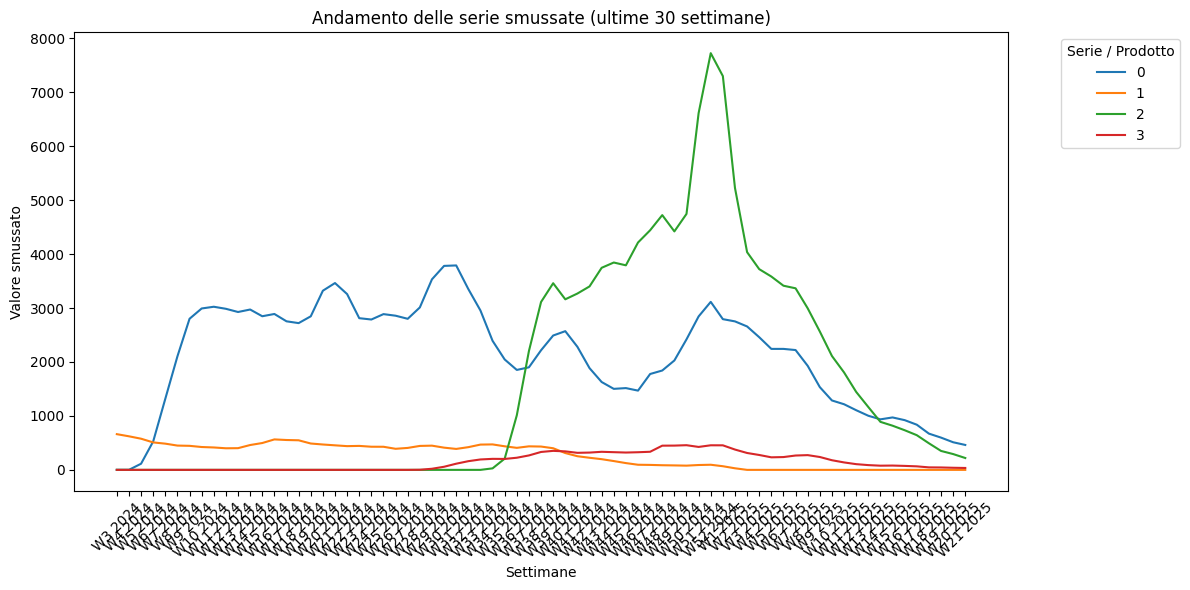

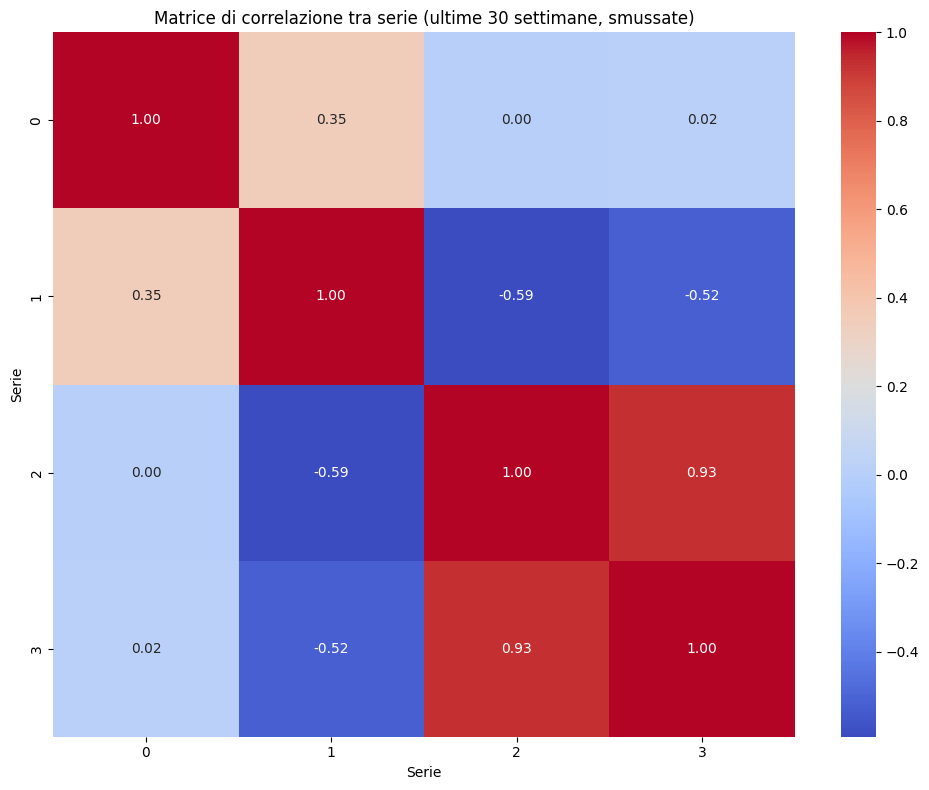

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- STEP 1: Selezione dati numerici e ultime 15 settimane ---
numeric_data = data.select_dtypes(include='number')

# Assicura che le colonne siano ordinate temporalmente
# (se le colonne sono stringhe come date, pandas le ordina correttamente se convertite)
#numeric_data.columns = pd.to_datetime(numeric_data.columns, errors='coerce')
#numeric_data = numeric_data.loc[:, numeric_data.columns.notna()]  # rimuove colonne non convertite
#numeric_data = numeric_data.sort_index(axis=1)

# Seleziona solo le ultime 15 settimane (colonne più recenti)
last_n_weeks = 30
selected_data = numeric_data.iloc[:, -last_n_weeks:]
selected_data = numeric_data
# --- STEP 2: Smoothing ---
smoothed_data = selected_data.rolling(window=3, axis=1).mean().dropna(axis=1)

# --- STEP 3: Plot serie con etichette ---
plt.figure(figsize=(12, 6))
smoothed_data_T = smoothed_data.T

for i, row_label in enumerate(smoothed_data.index):
    plt.plot(smoothed_data_T.iloc[:, i], label=row_label)

plt.title(f"Andamento delle serie smussate (ultime {last_n_weeks} settimane)")
plt.xlabel("Settimane")
plt.ylabel("Valore smussato")
plt.xticks(rotation=45)
plt.legend(title="Serie / Prodotto", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- STEP 4: Correlazione tra le serie ---
corr_matrix = smoothed_data.T.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, fmt=".2f")
plt.title(f"Matrice di correlazione tra serie (ultime {last_n_weeks} settimane, smussate)")
plt.xlabel("Serie")
plt.ylabel("Serie")
plt.tight_layout()
plt.show()


In [11]:
numeric_row.index

Index(['W1 2024', 'W2 2024', 'W3 2024', 'W4 2024', 'W5 2024', 'W6 2024',
       'W7 2024', 'W8 2024', 'W9 2024', 'W10 2024', 'W11 2024', 'W12 2024',
       'W13 2024', 'W14 2024', 'W15 2024', 'W16 2024', 'W17 2024', 'W18 2024',
       'W19 2024', 'W20 2024', 'W21 2024', 'W22 2024', 'W23 2024', 'W24 2024',
       'W25 2024', 'W26 2024', 'W27 2024', 'W28 2024', 'W29 2024', 'W30 2024',
       'W31 2024', 'W32 2024', 'W33 2024', 'W34 2024', 'W35 2024', 'W36 2024',
       'W37 2024', 'W38 2024', 'W39 2024', 'W40 2024', 'W41 2024', 'W42 2024',
       'W43 2024', 'W44 2024', 'W45 2024', 'W46 2024', 'W47 2024', 'W48 2024',
       'W49 2024', 'W50 2024', 'W51 2024', 'W52 2024', 'W1 2025', 'W2 2025',
       'W3 2025', 'W4 2025', 'W5 2025', 'W6 2025', 'W7 2025', 'W8 2025',
       'W9 2025', 'W10 2025', 'W11 2025', 'W12 2025', 'W13 2025', 'W14 2025',
       'W15 2025', 'W16 2025', 'W17 2025', 'W18 2025', 'W19 2025', 'W20 2025',
       'W21 2025'],
      dtype='object')

In [4]:
data.iloc[3, :].plot(figsize=(15, 5))

TypeError: no numeric data to plot